In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [30]:
df = pd.read_csv("uber.csv")

print(df.shape)
print(df.dtypes)
print(df.isnull().sum())
print(df.describe())

(200000, 9)
Unnamed: 0             int64
key                   object
fare_amount          float64
pickup_datetime       object
pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count        int64
dtype: object
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64
         Unnamed: 0    fare_amount  pickup_longitude  pickup_latitude  \
count  2.000000e+05  200000.000000     200000.000000    200000.000000   
mean   2.771250e+07      11.359955        -72.527638        39.935885   
std    1.601382e+07       9.901776         11.437787         7.720539   
min    1.000000e+00     -52.000000      -1340.648410       -74.015515   
25%    1.382535e+07       6.000000        -73.992065        40.734796   
50%    2.774550e+07       8.500000        -73.981823   

In [31]:
df = df.dropna()

df = df[(df["fare_amount"] > 0) & (df["fare_amount"] <= 200)]
df = df[df["passenger_count"].between(1, 6)]

df = df[
    df["pickup_longitude"].between(-75, -72) &
    df["dropoff_longitude"].between(-75, -72) &
    df["pickup_latitude"].between(40, 42) &
    df["dropoff_latitude"].between(40, 42)
].copy()

In [45]:
df

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,distance
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,1.683323
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2.457590
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,5.036377
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,1.661683
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,4.475450
...,...,...,...,...,...,...,...,...,...,...,...,...,...
199994,3189201,2014-01-31 14:42:00.000000181,12.0,2014-01-31 14:42:00+00:00,-73.983070,40.760770,-73.972972,40.754177,1,14,31,1,1.122878
199995,42598914,2012-10-28 10:49:00.00000053,3.0,2012-10-28 10:49:00+00:00,-73.987042,40.739367,-73.986525,40.740297,1,10,28,10,0.112210
199996,16382965,2014-03-14 01:09:00.0000008,7.5,2014-03-14 01:09:00+00:00,-73.984722,40.736837,-74.006672,40.739620,1,1,14,3,1.875050
199998,20259894,2015-05-20 14:56:25.0000004,14.5,2015-05-20 14:56:25+00:00,-73.997124,40.725452,-73.983215,40.695415,1,14,20,5,3.539715


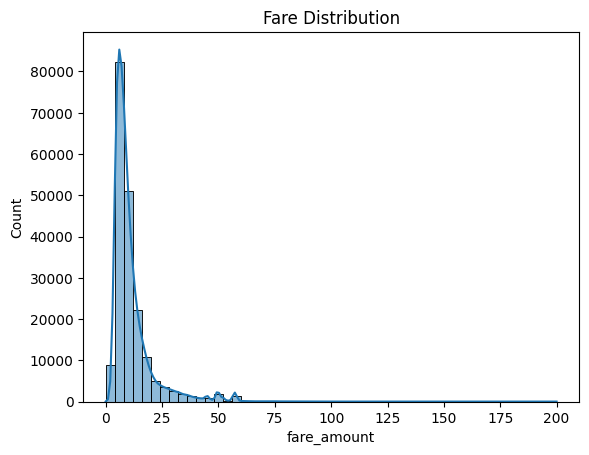

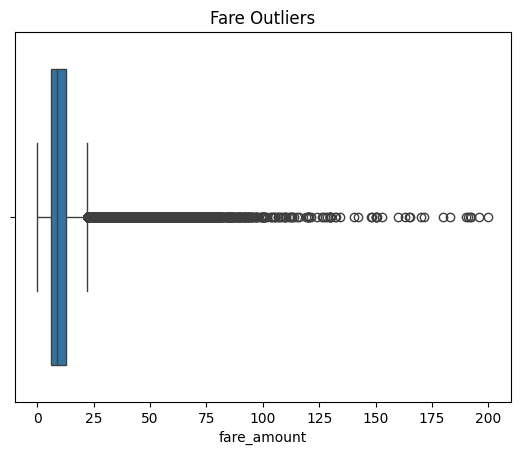

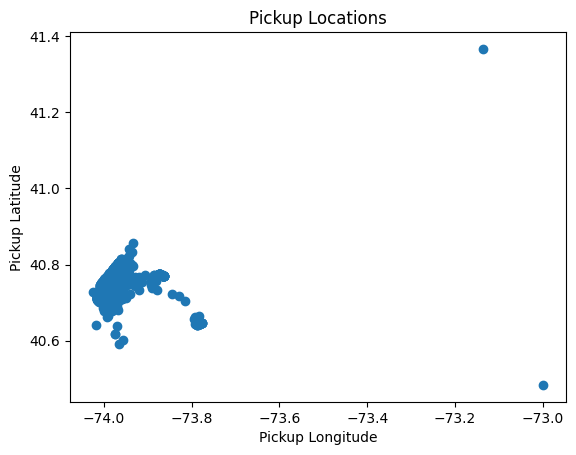

In [32]:
sns.histplot(df["fare_amount"], bins=50, kde=True)
plt.title("Fare Distribution")
plt.show()

sns.boxplot(x=df["fare_amount"])
plt.title("Fare Outliers")
plt.show()

plt.scatter( 
    df["pickup_longitude"].sample(min(2000, len(df)), random_state=42),
    df["pickup_latitude"].sample(min(2000, len(df)), random_state=42)
)
plt.xlabel("Pickup Longitude")
plt.ylabel("Pickup Latitude")
plt.title("Pickup Locations")
plt.show()

In [33]:
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[df["fare_amount"].between(lower, upper)].copy()

print("Shape after removing outliers:", df.shape)

Shape after removing outliers: (178392, 9)


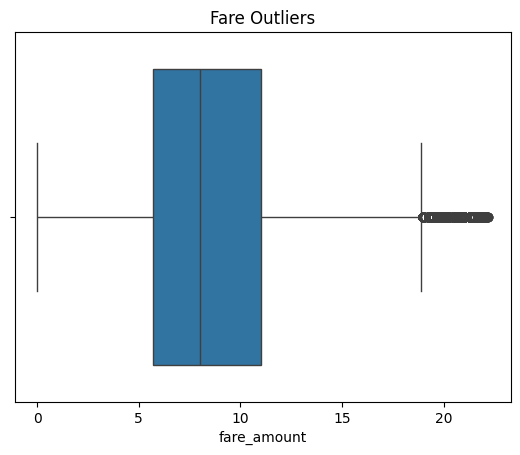

In [44]:
sns.boxplot(x=df["fare_amount"])
plt.title("Fare Outliers")
plt.show()

In [34]:
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], utc=True)

df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month

lat1 = np.radians(df["pickup_latitude"])
lon1 = np.radians(df["pickup_longitude"])
lat2 = np.radians(df["dropoff_latitude"])
lon2 = np.radians(df["dropoff_longitude"])

a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
df["distance"] = 6371 * 2 * np.arcsin(np.sqrt(a))

In [35]:
X = df.drop(
    columns=["fare_amount", "Unnamed: 0", "key", "pickup_datetime"],
    errors="ignore"
)

y = df["fare_amount"]

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (142713, 9)
Testing Features: (35679, 9)
Training Target: (142713,)
Testing Target: (35679,)


In [37]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [38]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

In [39]:
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original Features:", X_train_scaled.shape[1])
print("PCA Components:", pca.n_components_)
print("Explained Variance:", pca.explained_variance_ratio_.sum())

Original Features: 9
PCA Components: 8
Explained Variance: 0.9832984642459723


In [40]:
model_pca = LinearRegression()
model_pca.fit(X_train_pca, y_train)

y_pred_pca = model_pca.predict(X_test_pca)

In [41]:
print("WITHOUT PCA")
print("R2:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("MAE:", mean_absolute_error(y_test, y_pred))

print("\nWITH PCA")
print("R2:", r2_score(y_test, y_pred_pca))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_pca)))
print("MAE:", mean_absolute_error(y_test, y_pred_pca))

WITHOUT PCA
R2: 0.44214355259468974
RMSE: 3.093613471840642
MAE: 1.9039023429196826

WITH PCA
R2: 0.4373717906164901
RMSE: 3.106816289458028
MAE: 1.9049805326608145


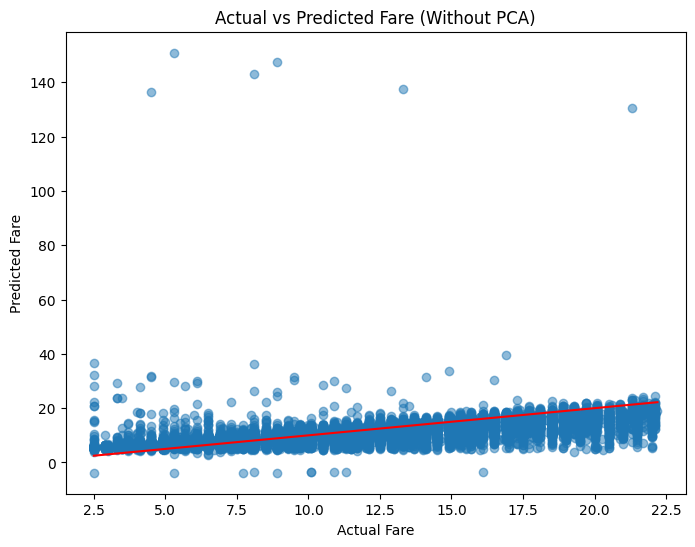

In [42]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], color="red")
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted Fare (Without PCA)")
plt.show()

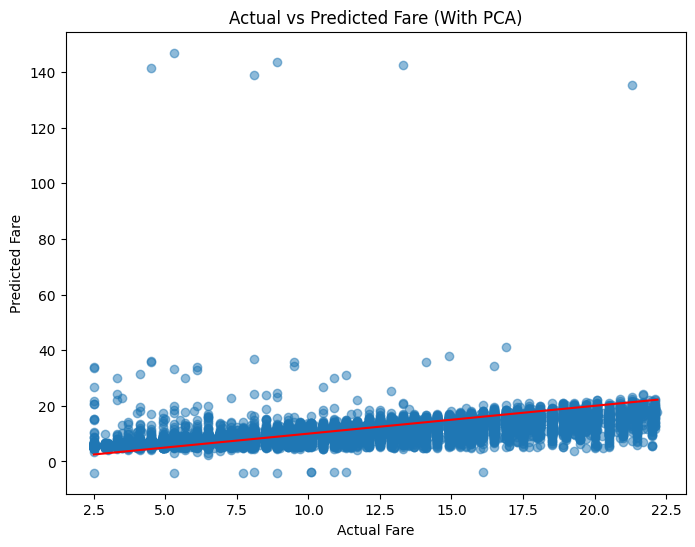

In [43]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_pca, alpha=0.5)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], color="red")
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted Fare (With PCA)")
plt.show()